# Analyse des départs clients — Portefeuille cartes de crédit

## Cadrage

**Contexte**
Une banque constate qu'une part importante de ses clients titulaires d'une carte de crédit résilie leur contrat. Le portefeuille étudié compte 10 127 clients, dont 1 627 sont partis (16,1 %).

**Question métier**
Quels clients risquent de partir, et quels signaux d'alerte la banque peut-elle surveiller pour agir avant le départ ?

**Axes d'analyse**
1. **Profil du client** : âge, sexe, situation familiale, niveau d'études, revenus, gamme de carte. Certains profils partent-ils davantage ?
2. **Utilisation de la carte** : montant et nombre de transactions, évolution de l'activité, encours, taux d'utilisation du plafond. Quels comportements précèdent un départ ?
3. **Relation avec la banque** : nombre de produits détenus, mois d'inactivité, contacts avec la banque. La relation se dégrade-t-elle avant le départ ?
4. **Ciblage** : quels groupes de clients prioriser, et combien de clients représentent-ils ?

**Indicateurs suivis**
- Taux de départ, global et par groupe de clients
- Écart au taux de référence (16,1 %)
- Nombre de clients concernés par chaque signal d'alerte

**Limites des données**
- Photographie à un instant donné : pas de date de départ, donc pas d'évolution dans le temps.
- Motif du départ non renseigné.
- Ancienneté peu fiable pour environ un quart des clients (voir notebook 01).
- Aucune donnée de rentabilité : la perte de revenus ne peut pas être chiffrée précisément.

**Livrables**
- Liste de signaux d'alerte, classés par niveau de risque
- Groupes de clients prioritaires pour les actions de fidélisation
- Tableau de bord Power BI de suivi

## Hypothèses métier

Hypothèses formulées avant l'exploration des données, à partir des motifs de départ fréquemment observés dans la relation bancaire : adéquation de l'offre, qualité du suivi, niveau des frais.

| # | Hypothèse | Indicateurs mobilisés | Vérifiable avec les données |
|---|---|---|---|
| H1 | Le client paie pour une offre qu'il utilise peu : les frais ne correspondent pas à son usage réel. | Montant et nombre de transactions, taux d'utilisation du plafond | Oui |
| H2 | La situation du client évolue sans que son offre soit ajustée, faute de suivi régulier. | Évolution de l'activité entre le 1er et le 4e trimestre | Partiellement : seule l'évolution de l'usage est visible |
| H3 | La relation est passive : le client n'est pas sollicité par son conseiller et ne se manifeste qu'en cas de difficulté. | Nombre de contacts, mois d'inactivité | Partiellement : l'origine des contacts n'est pas connue |
| H4 | Les produits détenus ne correspondent pas aux besoins réels du client. | Nombre de produits détenus, gamme de carte selon la tranche de revenu | Oui |
| H5 | Un client qui utilise fortement son crédit se sent moins valorisé par la banque. | Encours, taux d'utilisation du plafond | Approché : le découvert du compte courant n'est pas disponible |
| H6 | Les frais sont plus élevés que ceux de la concurrence. | — | Non : aucune donnée tarifaire. Sera traitée en recommandation |

Chaque hypothèse sera confirmée, nuancée ou infirmée au fil de l'analyse.

## 1. Préparation des données

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Chargement et exclusion des 2 colonnes de prédiction (voir notebook 01, section 2)
df = pd.read_csv("../data/BankChurners.csv")
df = df.loc[:, ~df.columns.str.startswith("Naive_Bayes")]

# Attrition_Flag : "Attrited Customer" = client parti → 1, "Existing Customer" = client actif → 0
df["parti"] = (df["Attrition_Flag"] == "Attrited Customer").astype(int)

# Taux de départ de référence, utilisé pour toutes les comparaisons
TAUX_REF = df["parti"].mean()

print(df.shape)
print(f"Taux de départ de référence : {TAUX_REF:.1%}")

(10127, 22)
Taux de départ de référence : 16.1%


**Préparation**
- Données chargées et contrôlées dans le notebook 01 : 10 127 clients, aucun doublon, aucune valeur manquante.
- Création d'un indicateur de départ (1 = client parti, 0 = client actif) : sa moyenne sur un groupe de clients donne directement le taux de départ de ce groupe.
- Taux de départ de référence : 16,1 %. Tout groupe situé nettement au-dessus de ce taux sera considéré comme à risque.

## 2. Axe 1 — Profil du client

In [4]:
# Fonction : nombre de clients et taux de départ pour chaque catégorie d'une colonne
def taux_par_groupe(colonne):
    return (df.groupby(colonne, observed=True)["parti"]
              .agg(nb_clients="size", taux_depart="mean")
              .round(3))

# Customer_Age : âge → regroupé en tranches
df["tranche_age"] = pd.cut(df["Customer_Age"], bins=[25, 35, 45, 55, 73],
                           labels=["26-35 ans", "36-45 ans", "46-55 ans", "56-73 ans"])

# Gender : sexe / Marital_Status : situation familiale / Education_Level : niveau d'études
# Income_Category : tranche de revenu / Card_Category : gamme de carte / Dependent_count : personnes à charge
for col in ["Gender", "tranche_age", "Marital_Status", "Education_Level",
            "Income_Category", "Card_Category", "Dependent_count"]:
    display(taux_par_groupe(col))

,nb_clients,taux_depart
Gender,,
F,5358,0.174
M,4769,0.146


,nb_clients,taux_depart
tranche_age,,
26-35 ans,919,0.133
36-45 ans,3742,0.162
46-55 ans,4135,0.166
56-73 ans,1331,0.159


,nb_clients,taux_depart
Marital_Status,,
Divorced,748,0.162
Married,4687,0.151
Single,3943,0.169
Unknown,749,0.172


,nb_clients,taux_depart
Education_Level,,
College,1013,0.152
Doctorate,451,0.211
Graduate,3128,0.156
High School,2013,0.152
Post-Graduate,516,0.178
Uneducated,1487,0.159
Unknown,1519,0.169


,nb_clients,taux_depart
Income_Category,,
$120K +,727,0.173
$40K - $60K,1790,0.151
$60K - $80K,1402,0.135
$80K - $120K,1535,0.158
Less than $40K,3561,0.172
Unknown,1112,0.168


,nb_clients,taux_depart
Card_Category,,
Blue,9436,0.161
Gold,116,0.181
Platinum,20,0.250
Silver,555,0.148


,nb_clients,taux_depart
Dependent_count,,
0,904,0.149
1,1838,0.146
2,2655,0.157
3,2732,0.176
4,1574,0.165
5,424,0.151


**Constat**
- Les taux de départ par critère de profil restent proches de la moyenne de 16,1 %, le plus souvent entre 14 % et 18 %.
- Les écarts les plus marqués concernent les femmes (17,4 % contre 14,6 % pour les hommes) et les titulaires d'un doctorat (21,1 %, soit 451 clients).
- La gamme Platinum affiche 25 % de départs, mais sur 20 clients seulement : ce résultat n'est pas exploitable.

**Enjeu métier**
- Le profil du client n'explique que faiblement les départs : une campagne de fidélisation ciblée uniquement sur l'âge, le revenu ou la situation familiale toucherait des clients à peine plus à risque que la moyenne.
- Le ciblage devra donc s'appuyer en priorité sur le comportement du client (utilisation de la carte, relation avec la banque), étudié dans les axes suivants.

## 3. Axe 2 — Utilisation de la carte

In [5]:
quarts = ["1er quart (le plus bas)", "2e quart", "3e quart", "4e quart (le plus haut)"]

# Total_Trans_Ct : nombre de transactions sur 12 mois
print("Seuils des quarts :", df["Total_Trans_Ct"].quantile([0.25, 0.5, 0.75]).round(2).tolist())
df["groupe_nb_transactions"] = pd.qcut(df["Total_Trans_Ct"], 4, labels=quarts)
display(taux_par_groupe("groupe_nb_transactions"))

# Total_Ct_Chng_Q4_Q1 : évolution du nombre de transactions entre le 1er et le 4e trimestre
print("Seuils des quarts :", df["Total_Ct_Chng_Q4_Q1"].quantile([0.25, 0.5, 0.75]).round(2).tolist())
df["groupe_evolution_transactions"] = pd.qcut(df["Total_Ct_Chng_Q4_Q1"], 4, labels=quarts)
display(taux_par_groupe("groupe_evolution_transactions"))

# Total_Revolving_Bal : encours (montant utilisé et non remboursé)
df["encours"] = (df["Total_Revolving_Bal"] > 0).map({True: "Avec encours", False: "Sans encours"})
display(taux_par_groupe("encours"))

Seuils des quarts : [45.0, 67.0, 81.0]


,nb_clients,taux_depart
groupe_nb_transactions,,
1er quart (le plus bas),2611,0.371
2e quart,2512,0.205
3e quart,2662,0.045
4e quart (le plus haut),2342,0.011


Seuils des quarts : [0.58, 0.7, 0.82]


,nb_clients,taux_depart
groupe_evolution_transactions,,
1er quart (le plus bas),2537,0.376
2e quart,2541,0.113
3e quart,2532,0.077
4e quart (le plus haut),2517,0.076


,nb_clients,taux_depart
encours,,
Avec encours,7657,0.096
Sans encours,2470,0.362


**Constat**
- **Nombre de transactions** : les 25 % de clients les moins actifs (45 transactions ou moins sur 12 mois) partent à 37,1 %, soit 2,3 fois plus que la moyenne. Les 25 % les plus actifs ne partent qu'à 1,1 %.
- **Évolution de l'activité** : les clients dont le nombre de transactions a le plus baissé entre le 1er et le 4e trimestre (activité réduite d'au moins 42 %) partent à 37,6 %, contre 7,6 % pour ceux dont l'activité est la plus stable.
- **Encours** : les 2 470 clients sans aucun encours partent à 36,2 %, contre 9,6 % pour les clients qui utilisent leur crédit.

**Hypothèses**
- **H1 confirmée** : un client qui utilise peu sa carte présente un risque de départ nettement plus élevé.
- **H2 confirmée sur l'usage** : une baisse d'activité au fil de l'année est un signal d'alerte fort.
- **H5 infirmée** : ce ne sont pas les clients qui utilisent fortement leur crédit qui partent le plus, mais ceux qui ne l'utilisent pas.

**Enjeu métier**
- L'utilisation de la carte constitue le signal d'alerte le plus puissant : contrairement au profil, elle distingue nettement les clients à risque.
- Ces indicateurs sont disponibles en continu dans les outils de la banque. Une baisse du nombre de transactions d'un trimestre à l'autre peut déclencher une alerte automatique vers le conseiller, avant que le client ne parte.
- Un client sans encours et peu actif est un client qui s'est déjà détourné de la carte : il doit être contacté en priorité, avec une offre adaptée à son usage réel.


## 4. Axe 3 — Relation avec la banque

In [6]:
# Total_Relationship_Count : nombre de produits détenus auprès de la banque
display(taux_par_groupe("Total_Relationship_Count"))

# Months_Inactive_12_mon : nombre de mois sans activité sur les 12 derniers mois
display(taux_par_groupe("Months_Inactive_12_mon"))

# Contacts_Count_12_mon : nombre de contacts avec la banque sur les 12 derniers mois
display(taux_par_groupe("Contacts_Count_12_mon"))

,nb_clients,taux_depart
Total_Relationship_Count,,
1,910,0.256
2,1243,0.278
3,2305,0.174
4,1912,0.118
5,1891,0.120
6,1866,0.105


,nb_clients,taux_depart
Months_Inactive_12_mon,,
0,29,0.517
1,2233,0.045
2,3282,0.154
3,3846,0.215
4,435,0.299
5,178,0.180
6,124,0.153


,nb_clients,taux_depart
Contacts_Count_12_mon,,
0,399,0.018
1,1499,0.072
2,3227,0.125
3,3380,0.201
4,1392,0.226
5,176,0.335
6,54,1.000


**Constat**
- **Produits détenus** : les clients ne détenant qu'1 ou 2 produits partent à plus de 25 %, contre 10 à 12 % pour ceux qui en détiennent 4 ou plus.
- **Inactivité** : le risque augmente avec la durée d'inactivité, de 4,5 % après 1 mois sans activité à 21,5 % après 3 mois et 29,9 % après 4 mois. Au-delà, les groupes sont trop petits pour conclure.
- **Contacts** : le taux de départ progresse régulièrement avec le nombre de contacts, de 1,8 % sans contact à 33,5 % pour 5 contacts. Les 54 clients ayant eu 6 contacts sont tous partis.

**Hypothèses**
- **H3 confirmée, avec une nuance** : les clients qui contactent souvent la banque partent davantage. Les contacts liés à la résiliation elle-même sont toutefois probablement inclus : le nombre de contacts est à la fois un signal d'alerte et une conséquence du départ.
- **H4 confirmée sur le niveau d'équipement** : un client peu équipé est nettement moins attaché à la banque. Le lien entre gamme de carte et revenus n'a pas pu être testé, les cartes haut de gamme (Gold, Platinum) étant trop peu nombreuses.

**Enjeu métier**
- Un client détenant 1 ou 2 produits est un client à équiper en priorité : chaque produit supplémentaire (épargne, assurance, compte) renforce son attachement à la banque.
- 3 mois d'inactivité constituent un seuil d'alerte concret, à partir duquel le conseiller doit reprendre contact.
- Un client qui sollicite la banque de façon répétée exprime une difficulté : ces contacts doivent être identifiés et traités comme un risque de départ, et pas seulement comme une demande isolée.

## 5. Axe 4 — Ciblage des clients à risque

In [7]:
# Les 6 signaux d'alerte identifiés dans les axes 2 et 3 (True = signal présent)
signaux = pd.DataFrame({
    "Activité faible": df["groupe_nb_transactions"] == "1er quart (le plus bas)",
    "Forte baisse d'activité": df["groupe_evolution_transactions"] == "1er quart (le plus bas)",
    "Sans encours": df["encours"] == "Sans encours",
    "1 ou 2 produits": df["Total_Relationship_Count"] <= 2,
    "3 mois d'inactivité ou plus": df["Months_Inactive_12_mon"] >= 3,
    "4 contacts ou plus": df["Contacts_Count_12_mon"] >= 4,
})

# Nombre de signaux cumulés par client
df["nb_signaux"] = signaux.sum(axis=1)

# Taux de départ selon le nombre de signaux
display(taux_par_groupe("nb_signaux"))

# Ciblage : clients cumulant au moins 3 signaux
cible = df["nb_signaux"] >= 3
print(f"Clients ciblés : {cible.sum()} ({cible.mean():.1%} du portefeuille)")
print(f"Taux de départ dans la cible : {df.loc[cible, 'parti'].mean():.1%}")
print(f"Part des départs couverts : {df.loc[cible, 'parti'].sum() / df['parti'].sum():.1%}")

,nb_clients,taux_depart
nb_signaux,,
0,1696,0.017
1,3654,0.043
2,2877,0.139
3,1243,0.398
4,473,0.795
5,157,0.917
6,27,1.000


Clients ciblés : 1900 (18.8% du portefeuille)
Taux de départ dans la cible : 54.8%
Part des départs couverts : 64.0%


**Constat**
- Le taux de départ augmente nettement avec le nombre de signaux d'alerte cumulés : 1,7 % sans aucun signal, 13,9 % avec 2 signaux, 39,8 % avec 3 signaux, et 79,5 % avec 4 signaux.
- Les 1 900 clients cumulant au moins 3 signaux représentent 18,8 % du portefeuille, mais 64,0 % des départs. Plus d'un sur deux est parti (54,8 %).

**Enjeu métier**
- En concentrant ses actions de fidélisation sur moins d'1 client sur 5, la banque peut toucher près des 2/3 des clients susceptibles de partir.
- La grille des 6 signaux repose sur des informations déjà disponibles et mises à jour en continu (transactions, encours, produits détenus, inactivité, contacts). Elle peut être intégrée aux outils des conseillers pour produire chaque mois une liste de clients à contacter.
- Le nombre de signaux permet de hiérarchiser les actions : un appel du conseiller dès 4 signaux, une offre personnalisée à partir de 3 signaux.

**Limites**
- Les seuils ont été définis et mesurés sur les mêmes données : leur efficacité devra être vérifiée sur une nouvelle période avant un déploiement.
- Le signal « 4 contacts ou plus » inclut probablement des contacts liés à la résiliation elle-même : il est plus fiable pour confirmer un risque que pour l'anticiper.

## 6. Synthèse

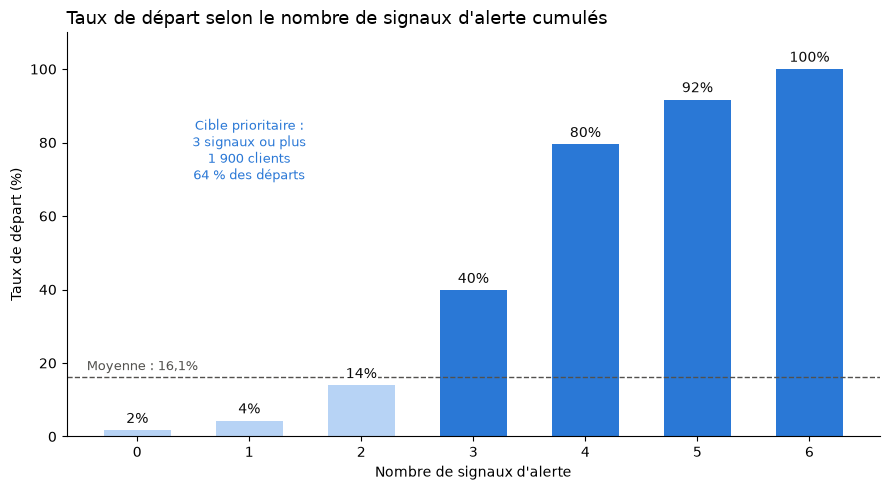

In [8]:
# Graphique de synthèse : taux de départ selon le nombre de signaux d'alerte
resume = taux_par_groupe("nb_signaux")
couleurs = ["#2a78d6" if n >= 3 else "#b7d3f5" for n in resume.index]  # foncé = cible prioritaire

fig, ax = plt.subplots(figsize=(9, 5))
barres = ax.bar(resume.index, resume["taux_depart"] * 100, color=couleurs, width=0.6)

# Valeur affichée au-dessus de chaque barre
for barre, taux in zip(barres, resume["taux_depart"]):
    ax.text(barre.get_x() + barre.get_width() / 2, taux * 100 + 2,
            f"{taux:.0%}", ha="center", fontsize=10, color="#0b0b0b",
            bbox=dict(facecolor="white", edgecolor="none", pad=1))

# Ligne du taux de référence
ax.axhline(TAUX_REF * 100, color="#52514e", linestyle="--", linewidth=1)
ax.text(-0.45, TAUX_REF * 100 + 2, f"Moyenne : {TAUX_REF:.1%}".replace(".", ","),
        fontsize=9, color="#52514e")

# Titres, axes et encadré de la cible
ax.set_title("Taux de départ selon le nombre de signaux d'alerte cumulés", fontsize=13, loc="left")
ax.set_xlabel("Nombre de signaux d'alerte")
ax.set_ylabel("Taux de départ (%)")
ax.set_ylim(0, 110)
ax.spines[["top", "right"]].set_visible(False)
ax.text(1, 70, "Cible prioritaire :\n3 signaux ou plus\n1 900 clients\n64 % des départs",
        fontsize=9, color="#2a78d6", ha="center")

plt.tight_layout()
plt.savefig("../images/taux_depart_par_signaux.png", dpi=150)
plt.show()

### Bilan des hypothèses

| # | Hypothèse | Verdict |
|---|---|---|
| H1 | Offre peu utilisée | ✅ Confirmée : les clients les moins actifs partent à 37,1 % |
| H2 | Situation qui évolue sans suivi | ✅ Confirmée sur l'usage : une forte baisse d'activité porte le taux de départ à 37,6 % |
| H3 | Relation passive | ✅ Confirmée avec nuance : le taux de départ croît avec le nombre de contacts, dont une partie est liée à la résiliation |
| H4 | Produits inadaptés aux besoins | ✅ Confirmée sur l'équipement : 1 ou 2 produits = plus de 25 % de départs |
| H5 | Forte utilisation du crédit | ❌ Infirmée : ce sont les clients sans encours qui partent le plus (36,2 %) |
| H6 | Frais supérieurs à la concurrence | ➖ Non testable : aucune donnée tarifaire |

### Conclusions

- **Le comportement prime sur le profil** : l'âge, le revenu ou la situation familiale ne distinguent presque pas les clients qui partent. Leur usage de la carte et leur relation avec la banque, si.
- **Les départs s'annoncent** : baisse d'activité, inactivité prolongée et contacts répétés sont visibles plusieurs mois avant la résiliation.
- **Une cible restreinte concentre le risque** : 1 900 clients (18,8 % du portefeuille) cumulent au moins 3 signaux d'alerte et représentent 64 % des départs.

### Recommandations

1. **Mettre en place une alerte mensuelle** fondée sur la grille des 6 signaux, transmise aux conseillers avec la liste des clients à contacter.
2. **Prioriser les appels** : contact du conseiller dès 4 signaux, offre personnalisée à partir de 3 signaux.
3. **Renforcer l'équipement** des clients détenant 1 ou 2 produits (épargne, assurance), pour consolider la relation.
4. **Relancer systématiquement** les clients après 3 mois d'inactivité.
5. **Traiter les contacts répétés** comme un risque de départ, et non comme des demandes isolées.
6. **Interroger les clients qui partent** sur leur motif (frais, offre concurrente, qualité du suivi), pour mesurer ce que les données actuelles ne permettent pas de voir.
7. **Fiabiliser la date d'entrée en relation** des clients concernés, pour intégrer l'ancienneté aux prochaines analyses.

## 7. Export des données pour Power BI

In [9]:
# Traduction des valeurs en français
sexe = {"F": "Femme", "M": "Homme"}
situation = {"Married": "Marié(e)", "Single": "Célibataire", "Divorced": "Divorcé(e)", "Unknown": "Inconnu"}
etudes = {"Uneducated": "Sans diplôme", "High School": "Niveau lycée", "College": "Bac +2",
          "Graduate": "Bac +3/4", "Post-Graduate": "Bac +5", "Doctorate": "Doctorat", "Unknown": "Inconnu"}
revenu = {"Less than $40K": "Moins de 40 K$", "$40K - $60K": "40 à 60 K$", "$60K - $80K": "60 à 80 K$",
          "$80K - $120K": "80 à 120 K$", "$120K +": "120 K$ et plus", "Unknown": "Inconnu"}

# Niveau de risque selon le nombre de signaux d'alerte
niveau_risque = pd.cut(df["nb_signaux"], bins=[-1, 1, 2, 3, 6],
                       labels=["Faible (0-1)", "Modéré (2)", "Élevé (3)", "Très élevé (4+)"])

# Table d'export : un client par ligne, colonnes en français
export = pd.DataFrame({
    "id_client": df["CLIENTNUM"],
    "statut": df["parti"].map({1: "Parti", 0: "Actif"}),
    "parti": df["parti"],
    "sexe": df["Gender"].map(sexe),
    "age": df["Customer_Age"],
    "tranche_age": df["tranche_age"],
    "situation_familiale": df["Marital_Status"].map(situation),
    "niveau_etudes": df["Education_Level"].map(etudes),
    "tranche_revenu": df["Income_Category"].map(revenu),
    "gamme_carte": df["Card_Category"],
    "nb_produits": df["Total_Relationship_Count"],
    "mois_inactivite": df["Months_Inactive_12_mon"],
    "nb_contacts": df["Contacts_Count_12_mon"],
    "plafond": df["Credit_Limit"],
    "encours": df["Total_Revolving_Bal"],
    "nb_transactions": df["Total_Trans_Ct"],
    "montant_transactions": df["Total_Trans_Amt"],
    "evolution_nb_transactions": df["Total_Ct_Chng_Q4_Q1"],
    "taux_utilisation": df["Avg_Utilization_Ratio"],
    "nb_signaux": df["nb_signaux"],
    "niveau_risque": niveau_risque,
    "cible_prioritaire": (df["nb_signaux"] >= 3).map({True: "Oui", False: "Non"}),
})

# Ajout des 6 signaux (1 = signal présent, 0 = absent)
export = pd.concat([export, signaux.astype(int)], axis=1)

# Contrôles avant export
print(export.shape)
print("Valeurs manquantes :", export.isna().sum().sum())
print(export["niveau_risque"].value_counts().sort_index())

# Export au format français (séparateur ; et virgule décimale) pour Power BI
export.to_csv("../data/clients_powerbi.csv", sep=";", decimal=",", index=False, encoding="utf-8-sig")

(10127, 28)
Valeurs manquantes : 0
niveau_risque
Faible (0-1)       5350
Modéré (2)         2877
Élevé (3)          1243
Très élevé (4+)     657
Name: count, dtype: int64


**Fichier produit** : `data/clients_powerbi.csv`, un client par ligne (10 127 clients, 28 colonnes).
- Colonnes et valeurs traduites en français, pour une lecture directe par les équipes métier.
- Chaque client porte ses 6 signaux d'alerte, son nombre de signaux, son niveau de risque (Faible, Modéré, Élevé, Très élevé) et son appartenance à la cible prioritaire.
- Les niveaux d'études sont traduits par équivalence approximative avec le système français.